# Wairagkar et al. 2025: exploring the source data

<img src="assets/experiment_illustration.png" alt="Brain-to-voice experiment overview" width="760">

Brain-to-voice speech neuroprosthesis (BrainGate2 participant **T15**, ALS, severe dysarthria). This notebook reads the **raw Dryad source** directly: per-session MATLAB files holding the pre-binned neural features, the two time-aligned LPCNet targets, the word and syllable timings, and the voice synthesized in closed loop during the evaluation sessions.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.wairagkar_2025 import study, utils
from neuralshed.datasets.utils import dataset_dir

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("wairagkar_2025") / "data"
s = study.Wairagkar2025Brain2Voice(path=root)
s.download()

data_dir = s.path / utils.DATA_SUBDIR
sessions = utils.list_sessions(data_dir)
total = sum(utils.n_trials(r) for r in sessions)
print(f"sessions: {len(sessions)} | evaluation sessions: {sum(r.is_eval for r in sessions)} | trials: {total}")
print(f"neural: {utils.N_ELECTRODES} ch ({', '.join(utils.ARRAY_ORDER)}) @ {utils.FS_NEURAL} Hz, {utils.NEURAL_BIN_SIZE_MS} ms bins")
print(f"LPCNet target: {utils.LPCNET_FEATURE_DIM} features | synthesized voice: {utils.SYNTH_AUDIO_FS} Hz (evaluation trials only)")

2026-10-15 12:09:26 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/wairagkar_2025/data/Wairagkar2025Brain2Voice.


2026-10-15 12:09:35 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/wairagkar_2025/data/Wairagkar2025Brain2Voice (skipped 0 non-owned items).


sessions: 37 | evaluation sessions: 9 | trials: 8489
neural: 256 ch (ventral_6v, 4, 55b, dorsal_6v) @ 100 Hz, 10 ms bins
LPCNet target: 20 features | synthesized voice: 16000 Hz (evaluation trials only)


## Sessions on disk

One folder per post-implant day. The nine evaluation sessions also hold the causal decoder that ran during the session, named for the session it was trained through.

In [2]:
df = pd.DataFrame([{"session": r.session, "day": r.day, "n_trials": utils.n_trials(r), "is_eval": r.is_eval,
                    "decoder": r.decoder_path.name if r.decoder_path else ""} for r in sessions])
print("trials per session: min", df.n_trials.min(), "median", int(df.n_trials.median()), "max", df.n_trials.max())
display(df.head(6))
display(df[df.is_eval])

trials per session: min 10 median 231 max 432


,session,day,n_trials,is_eval,decoder
0,t15_day025,25,312,False,
1,t15_day027,27,406,False,
2,t15_day032,32,275,False,
3,t15_day034,34,224,False,
4,t15_day039,39,131,False,
5,t15_day041,41,194,False,


,session,day,n_trials,is_eval,decoder
20,t15_day110,110,110,True,brain2voice_t15_day109.h5
29,t15_day172,172,293,True,brain2voice_t15_day165.h5
30,t15_day174,174,231,True,brain2voice_t15_day172.h5
31,t15_day179,179,296,True,brain2voice_t15_day174.h5
32,t15_day181,181,203,True,brain2voice_t15_day179.h5
33,t15_day186,186,319,True,brain2voice_t15_day181.h5
34,t15_day188,188,311,True,brain2voice_t15_day186.h5
35,t15_day193,193,432,True,brain2voice_t15_day188.h5
36,t15_day195,195,305,True,brain2voice_t15_day193.h5


## Trial types

Every trial carries a `trial_description`. Its seven values separate the training data from the closed-loop evaluation trials and their subtypes (preliminary, mimed, free response, spelling).

In [3]:
descr = pd.Series([d for r in sessions for d in utils.get_trial_descriptions(r)], name="trials")
display(descr.value_counts().to_frame())
r0 = sessions[0]
cues = utils.get_cues(r0)
print(f"{r0.session}: {len(cues)} trials | first cues: {cues[:3]}")

,count
trials,
Training data,6502
Evaluation trial,964
Training data (50-word vocab),771
Evaluation trial (preliminary),110
Evaluation trial (mimed speech),59
Evaluation trial (free response),52
Evaluation trial (spelling),31


t15_day025: 312 trials | first cues: ['How good are you?', 'Tell my nurse hello.', 'I clean it.']


## One trial: neural features and the LPCNet target

Top: the threshold-crossing half of the 512-wide neural input. Bottom: the word-aligned **LPCNet target** on the same 100 Hz grid. Vertical lines mark the word onsets (solid) and offsets (dotted) from `word_indices`.

In [4]:
TRIAL = 0
neural = utils.get_neural_features(r0, TRIAL, "both")      # (N, 512) = [spike-band power | threshold crossings]
target = utils.get_target_feats(r0, TRIAL, "word")         # (N, 20)
words = np.atleast_2d(utils.get_word_indices(r0, TRIAL))   # (n_words, 2), 100 Hz bin indices
n_bins = neural.shape[0]
dur = n_bins / utils.FS_NEURAL
print("cue    :", repr(cues[TRIAL]))
print("neural :", neural.shape, "| target:", target.shape, "| words:", words.shape, cues[TRIAL].split())

cue    : 'How good are you?'
neural : (857, 512) | target: (857, 20) | words: (4, 2) ['How', 'good', 'are', 'you?']


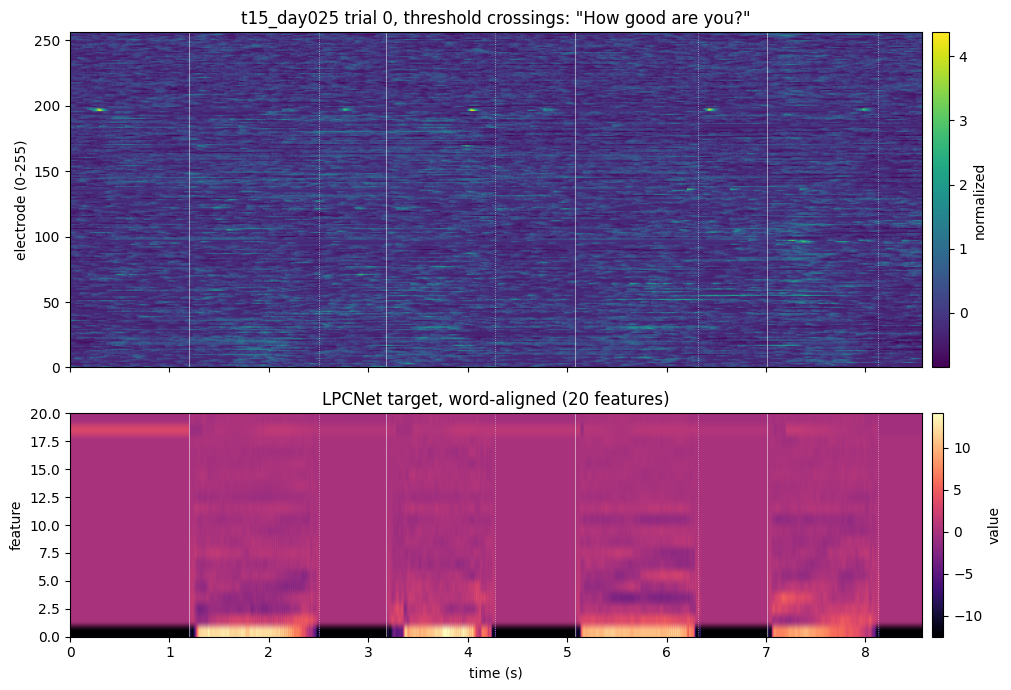

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
im0 = axes[0].imshow(neural[:, 256:].T, aspect="auto", origin="lower", cmap="viridis", extent=[0, dur, 0, 256])
axes[0].set(title=f'{r0.session} trial {TRIAL}, threshold crossings: "{cues[TRIAL]}"', ylabel="electrode (0-255)")
fig.colorbar(im0, ax=axes[0], pad=0.01, label="normalized")
im1 = axes[1].imshow(target.T, aspect="auto", origin="lower", cmap="magma", extent=[0, dur, 0, target.shape[1]])
axes[1].set(title="LPCNet target, word-aligned (20 features)", ylabel="feature", xlabel="time (s)")
fig.colorbar(im1, ax=axes[1], pad=0.01, label="value")
for on, off in words:
    for ax in axes:
        ax.axvline(on / utils.FS_NEURAL, color="w", lw=0.6, alpha=0.6)
        ax.axvline(off / utils.FS_NEURAL, color="w", lw=0.6, ls=":", alpha=0.6)
plt.tight_layout(); plt.show()

## Word-aligned vs syllable-aligned target

Both variants are the same text-to-speech rendering of the cue. The word-aligned one stretches each TTS word as a block onto the participant's word interval, the syllable-aligned one stretches each syllable separately, so the rhythm inside a word follows his attempt. They coincide when every word is monosyllabic. The paper's decoders trained on the syllable-aligned variant on every session after day 25.

t15_day097 trial 0: 'I found that all I talked about was my baby.' | 10 words, 13 syllables
bins where the two variants differ: 32%


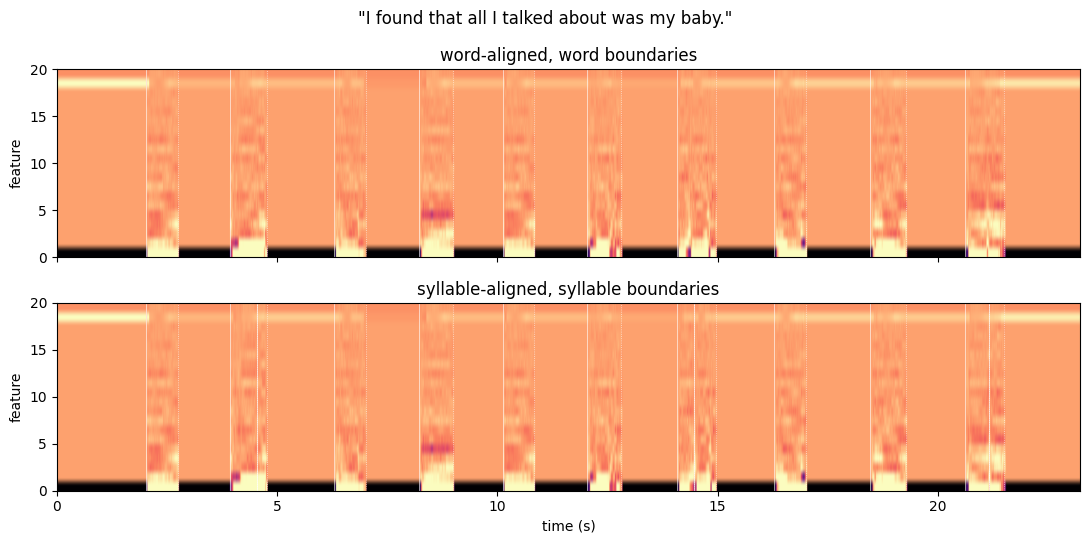

In [6]:
r97 = next(r for r in sessions if r.day == 97)
T97 = 0
cue97 = utils.get_cues(r97)[T97]
tw = utils.get_target_feats(r97, T97, "word")
ts = utils.get_target_feats(r97, T97, "syl")
w_idx = np.atleast_2d(utils.get_word_indices(r97, T97))
s_idx = np.atleast_2d(utils.get_syllable_indices(r97, T97))
dur97 = tw.shape[0] / utils.FS_NEURAL
print(f"{r97.session} trial {T97}: {cue97!r} | {len(w_idx)} words, {len(s_idx)} syllables")
print(f"bins where the two variants differ: {np.mean(np.any(tw != ts, axis=1)):.0%}")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
vmin, vmax = np.percentile(tw, 2), np.percentile(tw, 98)
for ax, M, idx, lab in zip(axes, [tw, ts], [w_idx, s_idx], ["word-aligned, word boundaries", "syllable-aligned, syllable boundaries"]):
    ax.imshow(M.T, aspect="auto", origin="lower", cmap="magma", vmin=vmin, vmax=vmax, extent=[0, dur97, 0, 20])
    for on, off in idx:
        ax.axvline(on / utils.FS_NEURAL, color="w", lw=0.6, alpha=0.7)
        ax.axvline(off / utils.FS_NEURAL, color="w", lw=0.6, ls=":", alpha=0.7)
    ax.set(ylabel="feature", title=lab)
axes[-1].set_xlabel("time (s)")
fig.suptitle(f'"{cue97}"')
plt.tight_layout(); plt.show()

## Synthesized voice (evaluation sessions)

The evaluation trials carry the voice synthesized in closed loop during the session, 160 samples per neural bin at 16 kHz. It is the online system's output, not a training target.

t15_day110 trial 0: 'Your voice is very nice.'
audio samples: 192960 = 1206 bins x 160 | decoder: brain2voice_t15_day109.h5


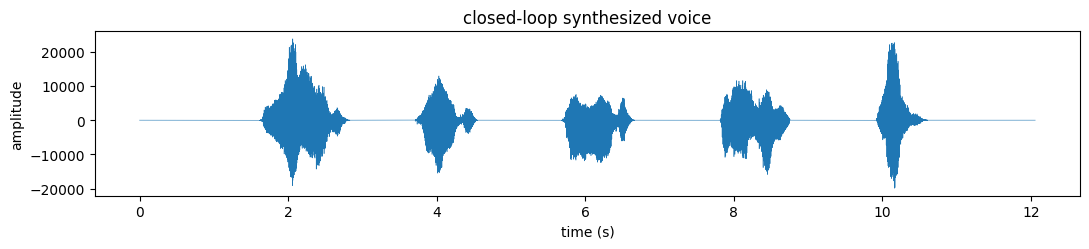

In [7]:
r_eval = next(r for r in sessions if r.is_eval)
T_EVAL = 0
wf = utils.get_pred_audio(r_eval, T_EVAL)
n_eval = utils.get_neural_features(r_eval, T_EVAL, "spikepow").shape[0]
print(f"{r_eval.session} trial {T_EVAL}: {utils.get_cues(r_eval)[T_EVAL]!r}")
print(f"audio samples: {wf.size} = {n_eval} bins x {wf.size // n_eval} | decoder: {r_eval.decoder_path.name}")
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot(np.arange(wf.size) / utils.SYNTH_AUDIO_FS, wf, lw=0.4)
ax.set(xlabel="time (s)", ylabel="amplitude", title="closed-loop synthesized voice")
plt.tight_layout(); plt.show()

## Listener-test trials (`test_idx.mat`)

Two lists of global trial indices (0-based over all sessions in day order) mark the evaluation trials whose synthesized voice was scored by human listeners: `random` is the 90-trial open-transcription test, `video` the 38 clips shown in the paper's videos. One trial is in both lists.

In [8]:
ti = utils.load_test_idx(data_dir)
offsets = np.cumsum([0] + df.n_trials.tolist()[:-1])   # first global index of each session

def locate(g):
    k = np.searchsorted(offsets, g, side="right") - 1
    return df.session.iloc[k], int(g - offsets[k])

both = np.intersect1d(ti["random"], ti["video"])
print("random:", len(ti["random"]), "| video:", len(ti["video"]), "| in both:", [locate(g) for g in both])
print("sessions with listener-test trials:", sorted({locate(g)[0] for g in np.concatenate([ti["random"], ti["video"]])}))

random: 90 | video: 38 | in both: [('t15_day179', 163)]
sessions with listener-test trials: ['t15_day110', 't15_day172', 't15_day174', 't15_day179', 't15_day181', 't15_day186', 't15_day188', 't15_day193', 't15_day195']


## Notes

- 37 sessions, 8,489 trials, one pre-cropped go-period clip per trial with no inter-trial timing. `02_explore_study.ipynb` builds the neuralset `Study` over them, one timeline per trial.
- The LPCNet target is synthesized from the cue text, not recorded. Word and syllable timings were measured from a microphone on day 25 and inferred from a previous decoder's synthesized output on every later session.
- The `t15_control_experiment` release (one session, 50-word vocabulary, stethoscope and IMU, no LPCNet target) is out of scope here.